# ЛР2 — формування та контроль якості датасету
Варіант 9: самоскиди, екскаватори, крани на майданчиках (обмежувальні рамки).

**Дані:** у цій версії набір **синтетичний** — 6 ортофотопланів будмайданчиків (5 ділянок,
одна ділянка знята двічі), згенерованих скриптом `synth_site.py` (GSD 0,05 м, EPSG:32635),
з еталонними рамками техніки. Для реальних даних — поклади GeoTIFF у `raw/` і заповни `scenes.csv`.
Кроки: 1) нарізання + маніфест → 2) розмітка в CVAT (поза ноутбуком) →
3) узгодженість → 4) розбиття + витоки → 5) статистика, хеш-суми, картка.

In [1]:
!pip -q install rasterio
import os, json, hashlib, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
SEED = 0
np.random.seed(SEED)
CLASSES = ["dump_truck", "excavator", "crane", "other_vehicle"]
ROOT = "dataset_cdw_v1"
os.makedirs(f"{ROOT}/images", exist_ok=True); os.makedirs(f"{ROOT}/labels", exist_ok=True)
os.makedirs(f"{ROOT}/stats", exist_ok=True)

## 1. Опис сцен
Заповни `scenes.csv` (по рядку на сцену). `site` — одна й та сама територія
(дві дати однієї ділянки мають однаковий `site`: так ми контролюємо часову залежність).

In [2]:
import sys; sys.path.append("../common"); sys.path.append(".")
from synth_site import make_site, clip_to_tile
import rasterio
from rasterio.transform import from_origin
os.makedirs("raw", exist_ok=True)
SCENE_SPECS = [  # scene, site, seed, дата, стиль (ґрунт RGB, освітлення)
    ("s01", "site1", 101, "2026-06-12", {"soil": [150, 130, 100], "light": 1.05}),
    ("s02", "site1", 102, "2026-07-03", {"soil": [145, 128, 98], "light": 0.95}),   # та сама ділянка, інша дата
    ("s03", "site2", 103, "2026-06-20", {"soil": [125, 110, 85], "light": 1.0}),
    ("s04", "site3", 104, "2026-08-01", {"soil": [165, 150, 125], "light": 1.1}),
    ("s05", "site4", 105, "2026-09-15", {"soil": [120, 115, 100], "light": 0.85}),
    ("s06", "site5", 106, "2026-10-02", {"soil": [140, 120, 90], "light": 1.0, "class_p": [.3, .25, .2, .25]}),
]
ORIGINS = {"site1": (286000, 5476000), "site2": (290000, 5476000), "site3": (294000, 5476000),
           "site4": (298000, 5476000), "site5": (302000, 5476000)}
GT = {}
rows_sc = []
for scene, site, seed, date, style in SCENE_SPECS:
    f = f"raw/{scene}.tif"
    img, objs = make_site(1920, 1920, gsd=0.05, seed=seed, style=style)
    GT[scene] = objs
    ox, oy = ORIGINS[site]
    if scene == "s02": ox, oy = ox + 30, oy - 30     # друга дата: зсув покриття на 30 м
    with rasterio.open(f, "w", driver="GTiff", height=1920, width=1920, count=3, dtype="uint8",
                       crs="EPSG:32635", transform=from_origin(ox, oy, 0.05, 0.05)) as d:
        d.write(img.transpose(2, 0, 1))
    rows_sc.append([f, scene, site, "synthetic (synth_site.py)", "UAV RGB (імітація)", 0.05, date, "власні синтетичні дані"])
pd.DataFrame(rows_sc, columns=["file", "scene", "site", "source", "sensor", "gsd_m", "date", "license"]).to_csv("scenes.csv", index=False)
scenes = pd.read_csv("scenes.csv"); scenes

,file,scene,site,source,sensor,gsd_m,date,license
0,raw/s01.tif,s01,site1,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-06-12,власні синтетичні дані
1,raw/s02.tif,s02,site1,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-07-03,власні синтетичні дані
2,raw/s03.tif,s03,site2,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-06-20,власні синтетичні дані
3,raw/s04.tif,s04,site3,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-08-01,власні синтетичні дані
4,raw/s05.tif,s05,site4,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-09-15,власні синтетичні дані
5,raw/s06.tif,s06,site5,synthetic (synth_site.py),UAV RGB (імітація),0.05,2026-10-02,власні синтетичні дані


## 2. Нарізання сцен на плитки з перекриттям (лістинг 2.1) і маніфест

In [3]:
import rasterio
from rasterio.warp import transform_bounds

def tile_offsets(H, W, size, overlap):
    step = size - overlap
    ys = sorted(set(range(0, max(H - size, 0), step)) | {max(H - size, 0)})
    xs = sorted(set(range(0, max(W - size, 0), step)) | {max(W - size, 0)})
    return [(y, x) for y in ys for x in xs]

def read_scene(path):
    if path.lower().endswith((".tif", ".tiff")):
        with rasterio.open(path) as src:
            img = np.transpose(src.read([1, 2, 3]), (1, 2, 0))
            if img.dtype != np.uint8:
                lo, hi = np.percentile(img[img > 0], (1, 99)); img = np.clip((img - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
            return img, src.transform, src.crs
    return np.array(Image.open(path).convert("RGB")), None, None

def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()

SIZE, OVERLAP = 640, 64
MAX_EMPTY_FRACTION = 0.5     # плитки, де > 50 % пікселів — nodata (чорне), відкидаємо
rows = []
for s in scenes.itertuples():
    img, tr, crs = read_scene(s.file)
    for (y0, x0) in tile_offsets(*img.shape[:2], SIZE, OVERLAP):
        t = img[y0:y0 + SIZE, x0:x0 + SIZE]
        if t.shape[0] < SIZE or t.shape[1] < SIZE or (t.sum(2) == 0).mean() > MAX_EMPTY_FRACTION:
            continue
        tid = f"{s.scene}_y{y0:05d}_x{x0:05d}"
        p = f"{ROOT}/images/{tid}.png"; Image.fromarray(t).save(p)
        b = [None] * 4
        if tr is not None:   # географічні межі плитки (EPSG:4326) — для перевірки просторового перекриття
            x_min, y_max = tr * (x0, y0); x_max, y_min = tr * (x0 + SIZE, y0 + SIZE)
            b = transform_bounds(crs, "EPSG:4326", x_min, y_min, x_max, y_max)
        rows.append(dict(tile_id=tid, scene=s.scene, site=s.site, source=s.source, sensor=s.sensor,
                         gsd_m=s.gsd_m, date=s.date, x=x0, y=y0, lon_min=b[0], lat_min=b[1],
                         lon_max=b[2], lat_max=b[3], license=s.license, sha256=sha256(p)))
manifest = pd.DataFrame(rows)
manifest.to_csv(f"{ROOT}/manifest.csv", index=False)
print(len(manifest), "плиток;", manifest.scene.nunique(), "сцен")
manifest.groupby("scene").size()

96 плиток; 6 сцен


scene
s01    16
s02    16
s03    16
s04    16
s05    16
s06    16
dtype: int64

## 3. Розмітка
Для синтетичного набору рамки беруться з генератора (еталон) за правилами `guideline_v1.md`:
об'єкт видно ≥ 50 % → рамка по видимій частині; менша сторона ≥ 10 пкс.
Формат — YOLO (`class xc yc w h`, нормовані). Для реальних даних — CVAT, експорт YOLO 1.1.

In [4]:
def write_yolo(path, objs, W=SIZE, H=SIZE):
    with open(path, "w") as f:
        for c, x0, y0, x1, y1 in objs:
            f.write(f"{c} {(x0 + x1) / 2 / W:.6f} {(y0 + y1) / 2 / H:.6f} {(x1 - x0) / W:.6f} {(y1 - y0) / H:.6f}\n")
for r in manifest.itertuples():
    write_yolo(f"{ROOT}/labels/{r.tile_id}.txt", clip_to_tile(GT[r.scene], r.x, r.y, SIZE))
print("файлів розмітки:", len(os.listdir(f"{ROOT}/labels")))

файлів розмітки: 96


### Імітація двох анотаторів для перевірки узгодженості
Людської розмітки синтетичного набору немає, тому узгодженість **змодельовано**: два незалежні
«анотатори» отримують еталон із шумом — зсув меж рамки, пропуск малих об'єктів, плутанина
схожих класів. Версія v1 інструкції — сильніший шум (неоднозначні правила), v2 — слабший
(уточнені правила для стріли екскаватора, бетонозмішувача, малих машин).

In [5]:
NOISE = {"v1": dict(jitter=6.0, miss_small=.30, miss=.05,
                    confuse={1: (3, .15), 0: (3, .10), 3: (0, .10), 2: (1, .12)}),
         "v2": dict(jitter=3.0, miss_small=.12, miss=.02,
                    confuse={1: (3, .05), 0: (3, .04), 3: (0, .04), 2: (1, .05)})}
def simulate(objs, cfg, rng):
    out = []
    for c, x0, y0, x1, y1 in objs:
        small = min(x1 - x0, y1 - y0) < 25
        if rng.random() < (cfg["miss_small"] if small else cfg["miss"]): continue
        if c in cfg["confuse"] and rng.random() < cfg["confuse"][c][1]: c = cfg["confuse"][c][0]
        j = rng.normal(0, cfg["jitter"], 4)
        if c == 1: j[[0, 2]] += rng.normal(0, cfg["jitter"] * 1.5, 2)   # межа стріли екскаватора
        b = np.clip([x0 + j[0], y0 + j[1], x1 + j[2], y1 + j[3]], 0, SIZE)
        if b[2] - b[0] > 4 and b[3] - b[1] > 4: out.append((c, *b))
    return out
rng = np.random.default_rng(SEED)
with_obj = [t for t in manifest.tile_id if os.path.getsize(f"{ROOT}/labels/{t}.txt") > 0]
pick = list(rng.choice(with_obj, 40, replace=False)); sets = {"v1": pick[:30], "v2": pick[30:]}
for ver, tiles in sets.items():
    for k in (1, 2):
        d = f"agreement/ann{k}" + ("" if ver == "v1" else "_v2"); os.makedirs(d, exist_ok=True)
        for t in tiles:
            r = manifest.set_index("tile_id").loc[t]
            write_yolo(f"{d}/{t}.txt", simulate(clip_to_tile(GT[r.scene], r.x, r.y, SIZE), NOISE[ver], rng))
print({v: len(t) for v, t in sets.items()})

{'v1': 30, 'v2': 10}


In [6]:
def read_yolo(path, W=SIZE, H=SIZE):
    out = []
    if os.path.exists(path):
        for line in open(path):
            p = line.split()
            if len(p) < 5: continue
            c, xc, yc, w, h = int(p[0]), *map(float, p[1:5])
            out.append((c, (xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H))
    return out

def iou(a, b):
    ix0, iy0 = max(a[0], b[0]), max(a[1], b[1]); ix1, iy1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix1 - ix0) * max(0, iy1 - iy0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

## 4. Узгодженість двох розміток (лістинг 2.2)
Для рамок: жадібне зіставлення за IoU ≥ 0,5 → F1 і середній IoU;
для класів збіжних пар → каппа Коена і матриця збігів.

In [7]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

def agreement(dir1, dir2, thr=0.5):
    tp = n1 = n2 = 0; ious = []; c1 = []; c2 = []
    for f in sorted(glob.glob(f"{dir1}/*.txt")):
        A = read_yolo(f); B = read_yolo(os.path.join(dir2, os.path.basename(f)))
        n1 += len(A); n2 += len(B); used = set()
        pairs = sorted(((iou(a[1:], b[1:]), i, j) for i, a in enumerate(A) for j, b in enumerate(B)), reverse=True)
        used_a = set()
        for v, i, j in pairs:
            if v < thr: break
            if i in used_a or j in used: continue
            used_a.add(i); used.add(j); tp += 1; ious.append(v); c1.append(A[i][0]); c2.append(B[j][0])
    P, R = tp / max(n2, 1), tp / max(n1, 1)
    f1 = 2 * P * R / max(P + R, 1e-9)
    kappa = cohen_kappa_score(c1, c2) if len(set(c1 + c2)) > 1 else float("nan")
    cm = pd.DataFrame(confusion_matrix(c1, c2, labels=range(len(CLASSES))), index=CLASSES, columns=CLASSES)
    print(f"рамок: ann1={n1}, ann2={n2}, збіжних={tp}")
    print(f"F1@IoU0.5 = {f1:.3f} | mean IoU = {np.mean(ious) if ious else float('nan'):.3f} | kappa(класи) = {kappa:.3f}")
    return cm

if os.path.isdir("agreement/ann1"):
    print("=== ДО уточнення інструкції ==="); display(agreement("agreement/ann1", "agreement/ann2"))
if os.path.isdir("agreement/ann1_v2"):
    print("=== ПІСЛЯ уточнення (10 плиток) ==="); display(agreement("agreement/ann1_v2", "agreement/ann2_v2"))

=== ДО уточнення інструкції ===
рамок: ann1=55, ann2=57, збіжних=54
F1@IoU0.5 = 0.964 | mean IoU = 0.790 | kappa(класи) = 0.815


,dump_truck,excavator,crane,other_vehicle
dump_truck,16,0,0,1
excavator,0,9,0,3
crane,0,0,5,0
other_vehicle,3,0,0,17


=== ПІСЛЯ уточнення (10 плиток) ===
рамок: ann1=27, ann2=26, збіжних=26
F1@IoU0.5 = 0.981 | mean IoU = 0.885 | kappa(класи) = 0.819


,dump_truck,excavator,crane,other_vehicle
dump_truck,6,0,0,2
excavator,0,12,0,0
crane,0,0,0,0
other_vehicle,0,1,0,5


## 5. Групове розбиття за ділянками (лістинг 2.3) + порівняння з випадковим

In [8]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

def dominant_label(tid):
    L = read_yolo(f"{ROOT}/labels/{tid}.txt")
    return CLASSES[np.bincount([l[0] for l in L]).argmax()] if L else "empty"

df = pd.read_csv(f"{ROOT}/manifest.csv")
df["label"] = df.tile_id.map(dominant_label)

def boxes_overlap(r, others):   # просторове перекриття плиток (геоприв'язані сцени)
    if pd.isna(r.lon_min) or others.lon_min.isna().all(): return False
    o = others.dropna(subset=["lon_min"])
    return bool(((o.lon_min < r.lon_max) & (o.lon_max > r.lon_min) &
                 (o.lat_min < r.lat_max) & (o.lat_max > r.lat_min)).any())

def leakage_report(train, other, name):
    same_site = other.site.isin(set(train.site)).mean()
    spatial = np.mean([boxes_overlap(r, train) for r in other.itertuples()]) if len(other) else 0
    print(f"  {name}: частка з тією ж ділянкою у train = {same_site:.2f}; з просторовим перекриттям = {spatial:.2f}")

# випадкове розбиття (для порівняння)
tr_r, rest_r = train_test_split(df, test_size=0.3, random_state=SEED)
va_r, te_r = train_test_split(rest_r, test_size=0.5, random_state=SEED)
print("=== Випадкове 70/15/15 ===", len(tr_r), len(va_r), len(te_r))
leakage_report(tr_r, va_r, "val"); leakage_report(tr_r, te_r, "test")

# групове: перебираємо зерна, поки кожен клас є в кожній підмножині
best = None
for seed in range(200):
    g = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    i_tr, i_rest = next(g.split(df, groups=df.site)); rest = df.iloc[i_rest]
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    i_va, i_te = next(g2.split(rest, groups=rest.site))
    tr, va, te = df.iloc[i_tr], rest.iloc[i_va], rest.iloc[i_te]
    ok = all(set(CLASSES) & set(df.label) <= set(s.label) for s in (tr, va, te))
    if ok: best = (seed, tr, va, te); break
if best is None:
    print("Не вдалося покрити всі класи в кожній підмножині — замало ділянок; беремо seed=0 і фіксуємо це в обмеженнях")
    best = (0, tr, va, te)
seed_used, tr, va, te = best
print(f"=== Групове за ділянками (seed={seed_used}) ===", len(tr), len(va), len(te),
      "| ділянок:", tr.site.nunique(), va.site.nunique(), te.site.nunique())
leakage_report(tr, va, "val"); leakage_report(tr, te, "test")

split = pd.Series("train", index=df.index); split[va.index] = "val"; split[te.index] = "test"
df["split"] = split; df["split_version"] = 1
df[["tile_id", "split", "split_version"]].to_csv(f"{ROOT}/split.csv", index=False)
dist = pd.crosstab(df.label, df.split)[["train", "val", "test"]]; display(dist)

=== Випадкове 70/15/15 === 67 14 15
  val: частка з тією ж ділянкою у train = 1.00; з просторовим перекриттям = 1.00
  test: частка з тією ж ділянкою у train = 1.00; з просторовим перекриттям = 1.00
=== Групове за ділянками (seed=5) === 48 16 32 | ділянок: 3 1 1
  val: частка з тією ж ділянкою у train = 0.00; з просторовим перекриттям = 0.00
  test: частка з тією ж ділянкою у train = 0.00; з просторовим перекриттям = 0.00


split,train,val,test
label,,,
crane,1,2,1
dump_truck,6,2,14
empty,23,6,12
excavator,13,4,4
other_vehicle,5,2,1


## 6. Пошук дублікатів за dHash (лістинг 2.4)

In [9]:
def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(im, dtype=float); return (a[:, 1:] > a[:, :-1]).flatten()

H = {t: dhash(f"{ROOT}/images/{t}.png") for t in df.tile_id}
ids = list(H); dup = []
for i, a in enumerate(ids):
    for b in ids[i + 1:]:
        d = int(np.sum(H[a] != H[b]))
        if d <= 6: dup.append((a, b, d))
sp = dict(zip(df.tile_id, df.split))
cross = [p for p in dup if sp[p[0]] != sp[p[1]]]
print("пар-дублікатів (d<=6):", len(dup), "| з них між різними підмножинами:", len(cross))
pd.DataFrame(dup, columns=["a", "b", "hamming"]).head(20)

пар-дублікатів (d<=6): 0 | з них між різними підмножинами: 0


,a,b,hamming


## 7. Статистика набору

зображень: 96 | об'єктів: 115


,objects,images,side_min_median
cls,,,
crane,11,10,126.65536
dump_truck,36,31,104.33216
excavator,38,29,120.39136
other_vehicle,30,23,79.93824


,tiles
scene,
s01,16
s02,16
s03,16
s04,16
s05,16
s06,16


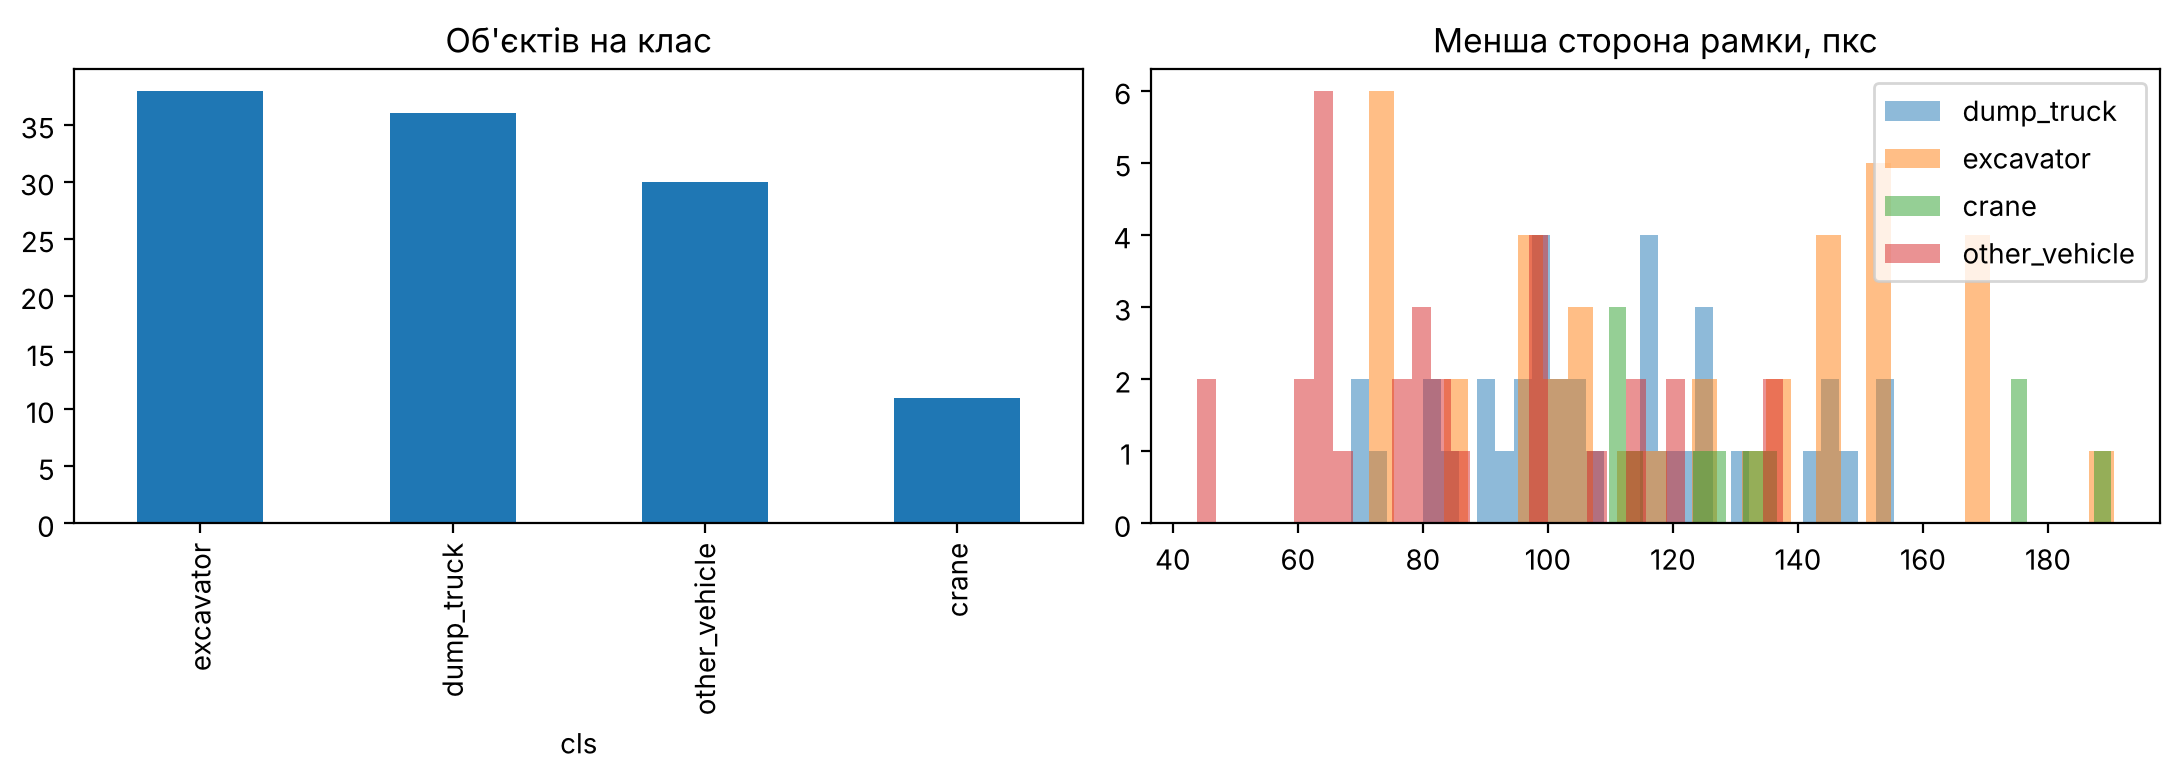

In [10]:
obj = []
for r in df.itertuples():
    for c, x0, y0, x1, y1 in read_yolo(f"{ROOT}/labels/{r.tile_id}.txt"):
        obj.append(dict(tile_id=r.tile_id, scene=r.scene, split=r.split, cls=CLASSES[c],
                        w=x1 - x0, h=y1 - y0, side_min=min(x1 - x0, y1 - y0)))
obj = pd.DataFrame(obj)
print("зображень:", len(df), "| об'єктів:", len(obj))
stats_cls = obj.groupby("cls").agg(objects=("cls", "size"), images=("tile_id", "nunique"),
                                   side_min_median=("side_min", "median"))
display(stats_cls); stats_cls.to_csv(f"{ROOT}/stats/classes.csv")
display(df.groupby("scene").size().rename("tiles").to_frame())
obj.groupby(["cls", "split"]).size().unstack(fill_value=0).to_csv(f"{ROOT}/stats/classes_by_split.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
obj.cls.value_counts().plot.bar(ax=ax[0], title="Об'єктів на клас")
for c in CLASSES:
    s = obj[obj.cls == c].side_min
    if len(s): ax[1].hist(s, bins=30, alpha=.5, label=c)
ax[1].set_title("Менша сторона рамки, пкс"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{ROOT}/stats/stats.png", dpi=150); plt.show()

## 8. Фіксація версії
Хеш-суми вже в `manifest.csv`. Для DVC (за бажанням):
```
pip install dvc && dvc init && dvc add dataset_cdw_v1/images && git add .
```
Перевірка відтворюваності: перезапусти ноутбук — `split.csv` має бути ідентичним (порівняй sha256).

In [11]:
print("sha256(split.csv) =", sha256(f"{ROOT}/split.csv"))

sha256(split.csv) = 04eb88ac25a386a0a3df71a886c253c2ed82a09063a3e784bd9317b530859bdc
